<a href="https://colab.research.google.com/github/kfartem434-png/MN_Kapusta/blob/main/%D0%9B%D0%A04_%D0%9A%D0%B0%D0%BF%D1%83%D1%81%D1%82%D0%B0_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler, PowerTransformer, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

In [ ]:
import kagglehub
import os

path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
df = pd.read_csv(os.path.join(path,"CarPrice_Assignment.csv"))

Using Colab cache for faster access to the 'car-price-prediction' dataset.


In [ ]:
df.shape

(205, 26)

In [ ]:
df.columns

Index(['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration',
       'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase',
       'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype',
       'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke',
       'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg',
       'price'],
      dtype='object')

In [ ]:
df.dtypes

,0
car_ID,int64
symboling,int64
CarName,object
fueltype,object
aspiration,object
doornumber,object
carbody,object
drivewheel,object
enginelocation,object
wheelbase,float64


In [ ]:
y = df["price"]
y

,price
0,13495.0
1,16500.0
2,16500.0
3,13950.0
4,17450.0
...,...
200,16845.0
201,19045.0
202,21485.0
203,22470.0


In [ ]:
df.describe()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [ ]:
df.isna().sum()

,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0


In [ ]:
print(df.duplicated().sum())

0


In [ ]:
print(df["car_ID"].duplicated().sum())

0


In [ ]:
df.nunique()

,0
car_ID,205
symboling,6
CarName,147
fueltype,2
aspiration,2
doornumber,2
carbody,5
drivewheel,3
enginelocation,2
wheelbase,53


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [ ]:
ids = df["car_ID"]

df.drop("car_ID",axis=1,inplace=True)

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


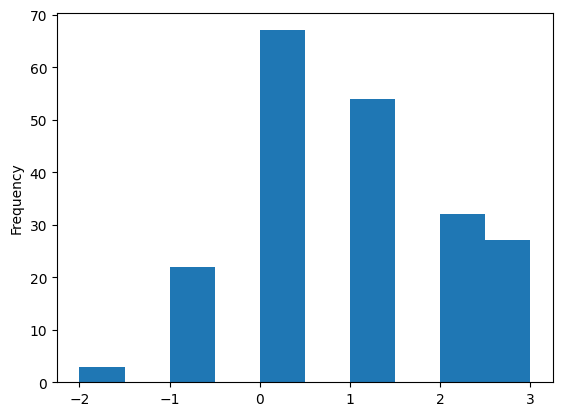

Коефіцієнт асиметрії: 0.21107227205788776


In [ ]:
df["symboling"].plot(kind="hist")
plt.show()
print("Коефіцієнт асиметрії:",df["symboling"].skew())

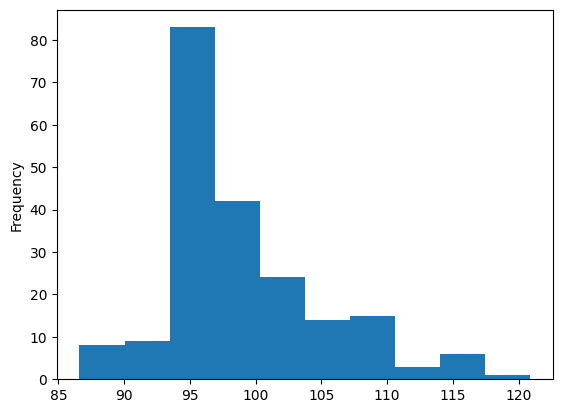

Коефіцієнт асиметрії: 1.0502137758714858


In [ ]:
df["wheelbase"].plot(kind="hist")
plt.show()
print("Коефіцієнт асиметрії:",df["wheelbase"].skew())

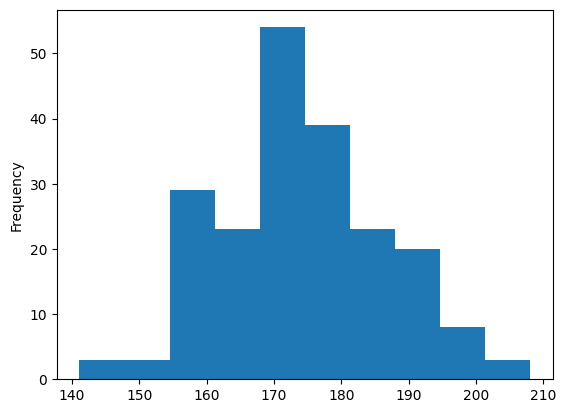

Коефіцієнт асиметрії: 0.1559537713215604


In [ ]:
df["carlength"].plot(kind="hist")
plt.show()
print("Коефіцієнт асиметрії:",df["carlength"].skew())

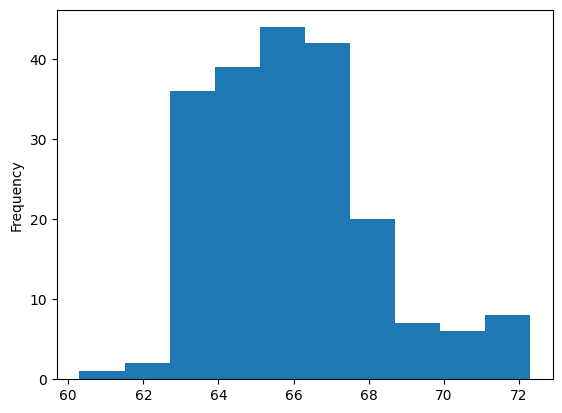

Коефіцієнт асиметрії: 0.904003498786254


In [ ]:
df["carwidth"].plot(kind="hist")
plt.show()
print("Коефіцієнт асиметрії:",df["carwidth"].skew())

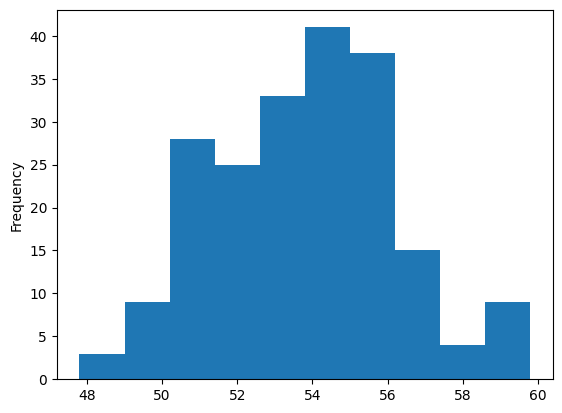

Коефіцієнт асиметрії: 0.06312273247192804


In [ ]:
df["carheight"].plot(kind="hist")
plt.show()
print("Коефіцієнт асиметрії:",df["carheight"].skew())

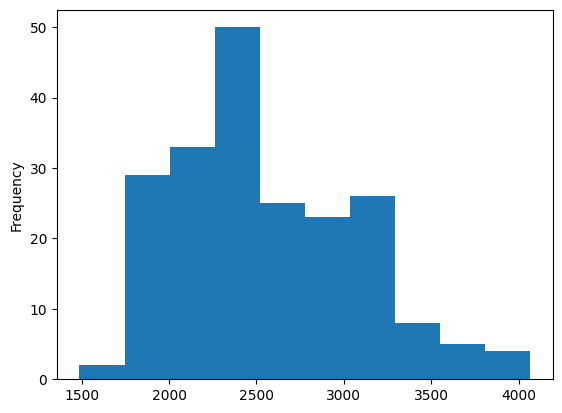

Коефіцієнт асиметрії: 0.681398189052588


In [ ]:
df["curbweight"].plot(kind="hist")
plt.show()
print("Коефіцієнт асиметрії:",df["curbweight"].skew())

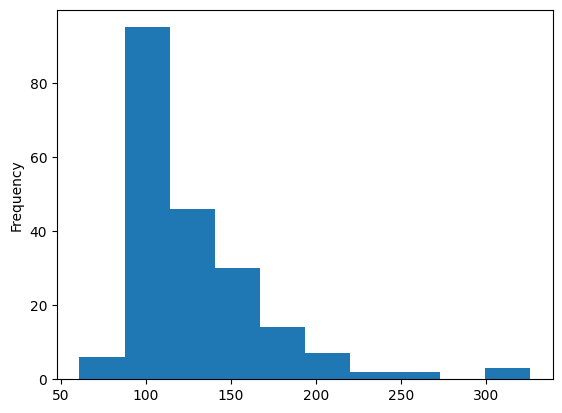

Коефіцієнт асиметрії: 1.9476550452788108


In [ ]:
df["enginesize"].plot(kind="hist")
plt.show()
print("Коефіцієнт асиметрії:",df["enginesize"].skew())

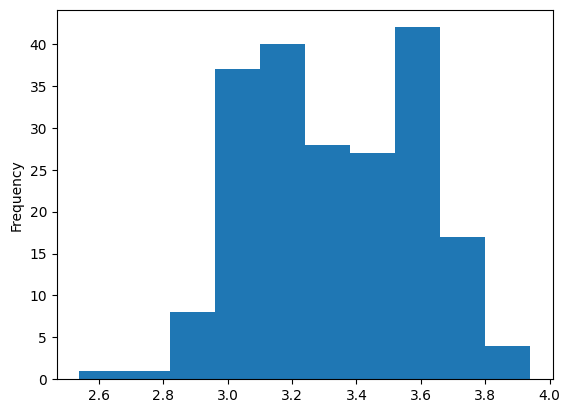

Коефіцієнт асиметрії: 0.02015641810424137


In [ ]:
df["boreratio"].plot(kind="hist")
plt.show()
print("Коефіцієнт асиметрії:",df["boreratio"].skew())

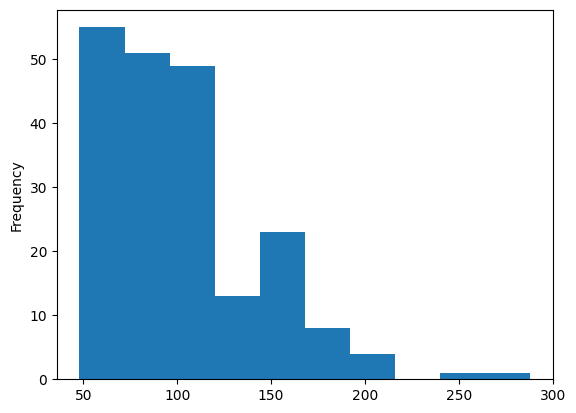

Коефіцієнт асиметрії: 1.4053101543373119


In [ ]:
df["horsepower"].plot(kind="hist")
plt.show()
print("Коефіцієнт асиметрії:",df["horsepower"].skew())

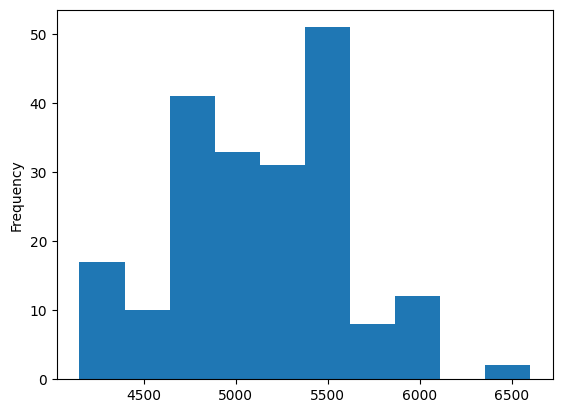

Коефіцієнт асиметрії: 0.07515872237118956


In [ ]:
df["peakrpm"].plot(kind="hist")
plt.show()
print("Коефіцієнт асиметрії:",df["peakrpm"].skew())

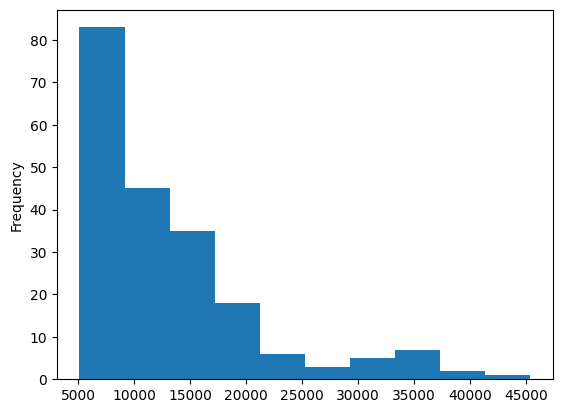

Коефіцієнт асиметрії: 1.7776781560914454


In [ ]:
df["price"].plot(kind="hist")
plt.show()
print("Коефіцієнт асиметрії:",df["price"].skew())

Ознаками з найбільшими коефіцієнтами асиметрії є: wheelbase, enginesize, horsepower та price. Всі ці ознаки мають високі, позитивні значення асиметрії, що слідчить про наявність більшої кількості автомобілів з гіршими фізичними ознаками та відповідно нижчими цінами.

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [ ]:
X = df.drop("price",axis=1)
y = df["price"]
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
  X,
  y,
  test_size=0.2,
  random_state=RANDOM_STATE
)

## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [ ]:
numeric_features = X_train[X_train.columns[(X_train.dtypes == np.float64) | (X_train.dtypes == np.int64)]].copy()

continuous_features = numeric_features.drop("symboling",axis=1)

q1 = continuous_features.quantile(0.25)
q3 = continuous_features.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5*iqr
higher = q3 + 1.5*iqr

outliers_train = continuous_features[
  (continuous_features < lower) | (continuous_features > higher)
].dropna(how="all")
continuous_features_test = X_test[
  X_test.columns[(X_test.dtypes == np.float64) | (X_test.dtypes == np.int64)]
].drop("symboling",axis=1)
outliers_test = continuous_features_test[
  (continuous_features_test < lower) | (continuous_features_test > higher)
].dropna(how="all")

In [ ]:
outliers_train.agg(lambda x: x.notna().sum(),axis=0)

,0
wheelbase,6
carlength,0
carwidth,10
carheight,0
curbweight,0
enginesize,7
boreratio,1
stroke,16
compressionratio,20
horsepower,7


In [ ]:
outliers_test.agg(lambda x: x.notna().sum(),axis=0)

,0
wheelbase,1
carlength,2
carwidth,2
carheight,0
curbweight,0
enginesize,3
boreratio,0
stroke,4
compressionratio,8
horsepower,1


In [ ]:
lowest = q1 - 6*iqr
highest = q3 + 6*iqr

outliers_train_to_delete = continuous_features[
  (continuous_features < lowest) | (continuous_features > highest)
].dropna(how="all")
outliers_test_to_delete = continuous_features_test[
  (continuous_features_test < lowest) | (continuous_features_test > highest)
].dropna(how="all")

print("До видалення:")
print("X_train:",len(X_train))
print("X_test",len(X_test))

X_train.drop(outliers_train_to_delete.index,axis=0,inplace=True)
y_train.drop(outliers_train_to_delete.index,axis=0,inplace=True)
X_test.drop(outliers_test_to_delete.index,axis=0,inplace=True)
y_test.drop(outliers_test_to_delete.index,axis=0,inplace=True)

print("Після видалення:")
print("X_train:",len(X_train))
print("X_test:",len(X_test))

До видалення:
X_train: 164
X_test 41
Після видалення:
X_train: 149
X_test: 36


Для видалення було обрано тільки значення з екстремальними відхиленнями; для видалення було обрано не всі потенційні викиди, так як для малих датасетів, як наприклад датасет цієї роботи, вони можуть мати у собі корисну для дослідження інформацію.

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


In [ ]:
numeric_correlations_matrix = numeric_features.corr()

high_correlations_matrix = numeric_correlations_matrix[abs(numeric_correlations_matrix) > 0.85]
high_correlations_matrix.mask(np.identity(len(high_correlations_matrix),dtype=np.bool),inplace=True)
high_correlations_matrix.dropna(how="all",axis=0,inplace=True)
high_correlations_matrix.dropna(how="all",axis=1,inplace=True)
high_correlations_matrix

,wheelbase,carlength,curbweight,citympg,highwaympg
wheelbase,NaN,0.866698,NaN,NaN,NaN
carlength,0.866698,NaN,0.865988,NaN,NaN
curbweight,NaN,0.865988,NaN,NaN,NaN
citympg,NaN,NaN,NaN,NaN,0.964812
highwaympg,NaN,NaN,NaN,0.964812,NaN


In [ ]:
high_correlation_pairs = set()
for col, ser in high_correlations_matrix.items():
  for i, val in ser.items():
    if not np.isnan(val):
      high_correlation_pairs.add(frozenset([col,i]))

print(high_correlation_pairs)

{frozenset({'citympg', 'highwaympg'}), frozenset({'carlength', 'wheelbase'}), frozenset({'carlength', 'curbweight'})}


In [ ]:
correlations_with_target = numeric_features.apply(pd.Series.corr,axis=0,args=(y_train,))
abs_correlations_with_target = abs(correlations_with_target)
abs_correlations_with_target.sort_values(ascending=False,inplace=True)
abs_correlations_with_target

,0
enginesize,0.870080
horsepower,0.840390
curbweight,0.832363
citympg,0.767260
highwaympg,0.758329
carwidth,0.738896
carlength,0.648475
boreratio,0.558835
wheelbase,0.491525
compressionratio,0.097789


In [ ]:
features_to_delete = []
for corr_pair in high_correlation_pairs:
  for indx, target_corr in abs_correlations_with_target.items():
    if indx in corr_pair:
      features_to_delete.append(indx)
      break

features_to_delete

['citympg', 'carlength', 'curbweight']

In [ ]:
for feature in features_to_delete:
  X_train.drop(feature,axis=1,inplace=True)
  X_test.drop(feature,axis=1,inplace=True)

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [ ]:
numeric_features = X_train[X_train.columns[(X_train.dtypes == np.float64) | (X_train.dtypes == np.int64)]].copy()

continuous_features = numeric_features.drop("symboling",axis=1)

In [ ]:
continuous_features

,wheelbase,carwidth,carheight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,highwaympg
111,107.9,68.4,56.7,120,3.46,2.19,8.4,95,5000,24
153,95.7,63.6,59.1,92,3.05,3.03,9.0,62,4800,37
96,94.5,63.8,54.5,97,3.15,3.29,9.4,69,5200,37
38,96.5,65.2,53.3,110,3.15,3.58,9.0,86,5800,33
24,93.7,63.8,50.6,90,2.97,3.23,9.4,68,5500,38
...,...,...,...,...,...,...,...,...,...,...
106,99.2,67.9,49.7,181,3.43,3.27,9.0,160,5200,25
14,103.5,66.9,55.7,164,3.31,3.19,9.0,121,4250,25
92,94.5,63.8,54.5,97,3.15,3.29,9.4,69,5200,37
179,102.9,67.7,52.0,171,3.27,3.35,9.3,161,5200,24


In [ ]:
discrete_feature = X_train["symboling"].copy()
discrete_feature

,symboling
111,0
153,0
96,1
38,0
24,1
...,...
106,1
14,1
92,1
179,3


In [ ]:
categorical_features = X_train.drop(numeric_features.columns,axis=1)
categorical_features

,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,enginetype,cylindernumber,fuelsystem
111,peugeot 504,gas,std,four,sedan,rwd,front,l,four,mpfi
153,toyota corona hardtop,gas,std,four,wagon,fwd,front,ohc,four,2bbl
96,nissan latio,gas,std,four,sedan,fwd,front,ohc,four,2bbl
38,honda civic 1300,gas,std,two,hatchback,fwd,front,ohc,four,1bbl
24,dodge monaco (sw),gas,std,four,hatchback,fwd,front,ohc,four,2bbl
...,...,...,...,...,...,...,...,...,...,...
106,nissan clipper,gas,std,two,hatchback,rwd,front,ohcv,six,mpfi
14,bmw z4,gas,std,four,sedan,rwd,front,ohc,six,mpfi
92,nissan latio,gas,std,four,sedan,fwd,front,ohc,four,2bbl
179,toyota corona,gas,std,two,hatchback,rwd,front,dohc,six,mpfi


In [ ]:
continuous_pipe = Pipeline([
  ("transform",PowerTransformer()),
  ("scale",StandardScaler()),
])

discrete_pipe = Pipeline([
  ("scale",StandardScaler()),
])

categories_train = categorical_features.apply(pd.Series.unique,axis=0)
categories_test = X_test.drop(numeric_features.columns,axis=1).apply(pd.Series.unique,axis=0)

categories = list(map(lambda x,y: x | y,map(set,categories_train.tolist()),map(set,categories_test.tolist())))
categories = list(map(list,categories))

categorical_pipe = Pipeline([
  ("onehot",OneHotEncoder(categories=categories))
])

continuous_features_list = continuous_features.columns.tolist()
discrete_features_list = [discrete_feature.name,]
categorical_features_list = categorical_features.columns.tolist()

preprocessor = ColumnTransformer([
  ("continuous",continuous_pipe,continuous_features_list),
  ("discrete",discrete_pipe,discrete_features_list),
  ("categorical",categorical_pipe,categorical_features_list)
])

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [ ]:
transformed_X_train = X_train.copy()
transformed_continuous_features = continuous_pipe.fit_transform(transformed_X_train[continuous_features_list])

old_skews = X[X.columns[(X.dtypes == np.float64) | (X.dtypes == np.int64)]].skew()
transformed_skews = pd.DataFrame(transformed_continuous_features,columns=continuous_pipe.feature_names_in_).skew()

skews = pd.DataFrame([old_skews,transformed_skews],index=["old_skews","transformed_skews"])
skews

,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg
old_skews,0.211072,1.050214,0.155954,0.904003,0.063123,0.681398,1.947655,0.020156,-0.689705,2.610862,1.405310,0.075159,0.663704,0.539997
transformed_skews,NaN,-0.009704,NaN,0.513454,0.001529,NaN,0.035340,-0.004983,0.126408,0.148427,0.103465,0.003250,NaN,-0.017328


Як видно з таблиці, перетворення що будуть використані у препроцесингу моделей зменшує коефіцієнти асиметрії.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [ ]:
models = {
  "linear": Pipeline([
    ("prep",preprocessor),
    ("reg",LinearRegression())
  ]),
  "ridge": Pipeline([
    ("prep",preprocessor),
    ("reg",Ridge())
  ]),
  "lasso": Pipeline([
    ("prep",preprocessor),
    ("reg",Lasso())
  ]),
  "random_forest": Pipeline([
    ("prep",preprocessor),
    ("reg",RandomForestRegressor())
  ]),
  "gradient_boosting": Pipeline([
    ("prep",preprocessor),
    ("reg",GradientBoostingRegressor())
  ]),
  "svr": Pipeline([
    ("prep",preprocessor),
    ("reg",SVR())
  ]),
}

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [ ]:
predictions = dict()
metrics = dict()
for name, model in models.items():
  model.fit(X_train,y_train)
  prediction = model.predict(X_test)
  predictions[name] = prediction
  metrics[name] = (
    r2_score(y_test,prediction),
    mean_absolute_error(y_test,prediction),
    mean_squared_error(y_test,prediction),
    mean_absolute_percentage_error(y_test,prediction)*100
  )

In [ ]:
metrics_table = pd.DataFrame(metrics,index=["R2","MAE","MSE","MAPE%"]).T.sort_values("R2",ascending=False)
metrics_table

,R2,MAE,MSE,MAPE%
gradient_boosting,0.949606,1428.448116,3.593922e+06,12.033757
random_forest,0.946087,1457.510083,3.844926e+06,11.423276
ridge,0.716338,2956.213969,2.022988e+07,26.856277
lasso,0.636008,2864.558690,2.595873e+07,22.967506
linear,0.290411,4293.750019,5.060565e+07,35.594854
svr,-0.079145,4875.100039,7.696118e+07,32.012238


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Модель Logistic Regression є класифікаційним алгоритмом, тобто вона створена для призначення ярликів на вхідну інформацію. Прогнозування price, тобто неперервної змінної, натомість, є задачею регресії, для якої підходять моделі спеціально створені для вирішення подібного сорту задач.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


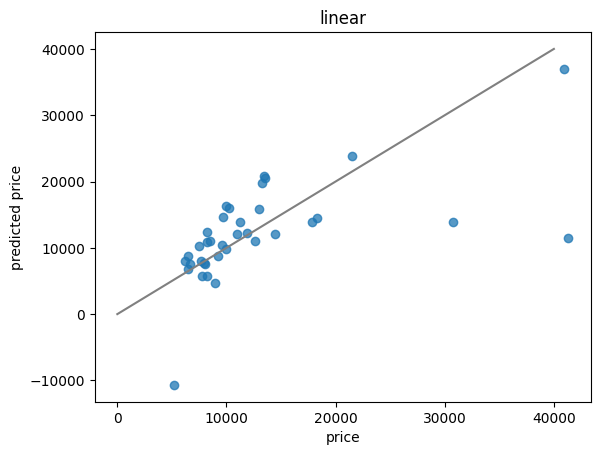

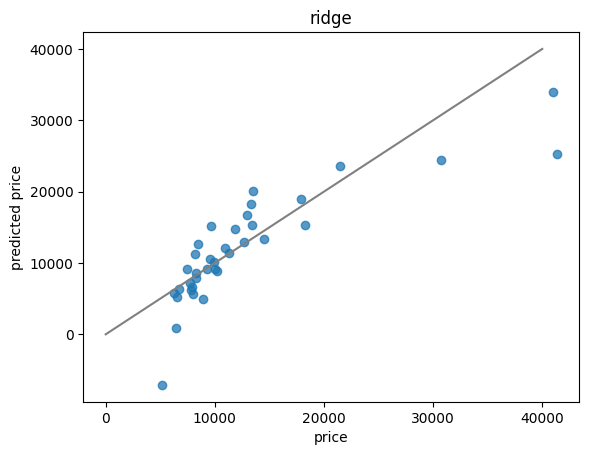

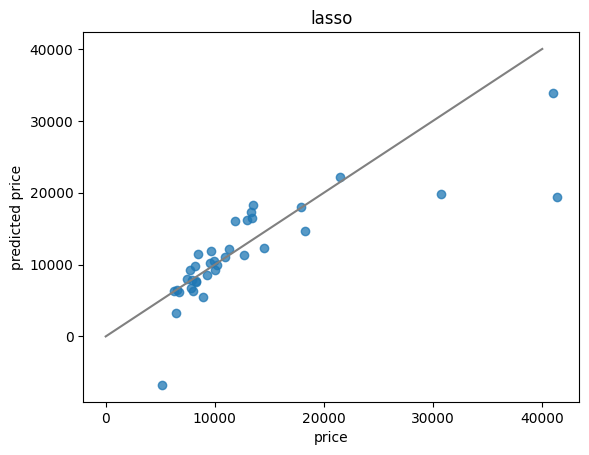

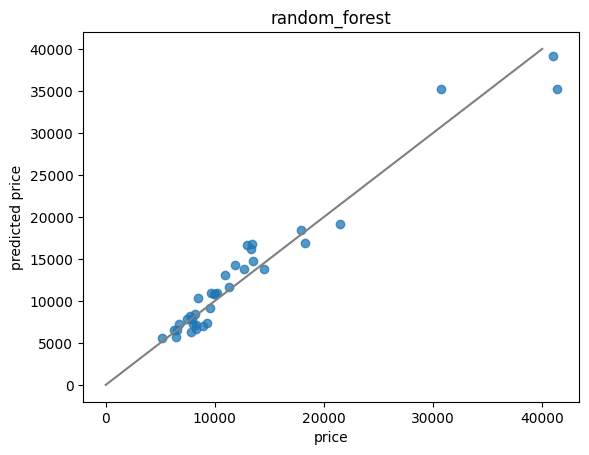

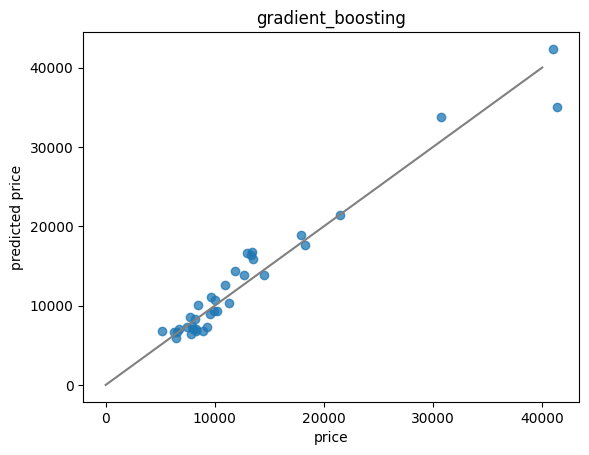

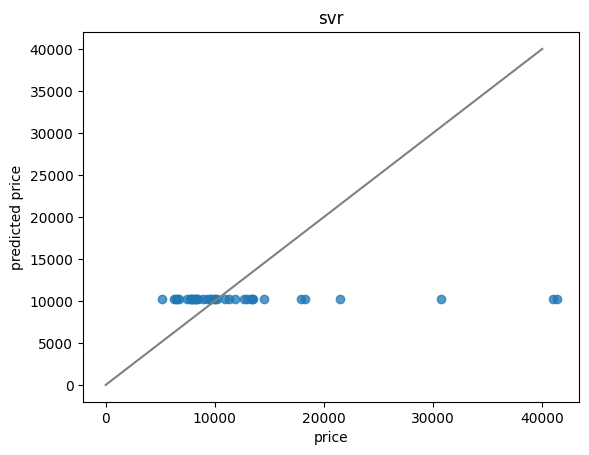

In [ ]:
for name, prediction in predictions.items():
  fig, ax = plt.subplots()
  ax.scatter(y_test,prediction,alpha=0.75)
  ax.plot([0,40000],[0,40000],color="gray")
  plt.xlabel("price")
  plt.ylabel("predicted price")
  plt.title(name)
  plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [ ]:
X_test_10 = X_test.sample(10,random_state=RANDOM_STATE)
y_pred_10 = models["random_forest"].predict(X_test_10)
id_10 = ids[X_test_10.index]

pred_10 = pd.DataFrame(
  {
    "car_ID": id_10,
    "true_price": y_test[X_test_10.index],
    "predicted_price": y_pred_10,
    "absolute_error": y_pred_10 - y_test[X_test_10.index],
    "absolute_percent_error": 100*(y_pred_10 - y_test[X_test_10.index])/y_test[X_test_10.index]
  }
)
pred_10

,car_ID,true_price,predicted_price,absolute_error,absolute_percent_error
146,147,7463.0,7842.22,379.22,5.081335
18,19,5151.0,5599.31,448.31,8.703359
194,195,12940.0,16712.32,3772.32,29.152396
79,80,7689.0,8206.48,517.48,6.730134
143,144,9960.0,10879.47,919.47,9.231627
145,146,11259.0,11640.72,381.72,3.390354
25,26,6692.0,7194.85,502.85,7.514196
152,153,6488.0,6525.30,37.30,0.574908
164,165,8238.0,7103.15,-1134.85,-13.775795
60,61,8495.0,10353.68,1858.68,21.879694


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Найкращі результати показали моделі Gradient Boosting та Random Forest, з показниками R2 близько 95% та найнижчими показниками MAE, MSE та MAPE. Linear, Ridge і Lasso показали погані результати: Ridge та Lasso мають R2 в районі 60-70%, R2 для Linear -- близько 30%. З графіків видно, що значення даних помилок спричинені викидами у передбачених значеннях price -- три спостереження з правої частини від основного кластеру та одне зліва, є нижчими за лінію ідеального прогнозу, що може слідчити про недонавчання цих моделей. В цілому, найкращою моделю є Gradient Boosting, яка має порівняно однакове значення R2 з Random Forest, але менші значення MAE, MSE та MAPE.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
